In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("Wersja TensorFlow:", tf.__version__)
print("Dostępne GPU:", tf.config.list_physical_devices("GPU"))

Wersja TensorFlow: 2.21.0
Dostępne GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from google.colab import files

uploaded = files.upload()

Saving cechy_tekstur.csv to cechy_tekstur.csv


In [4]:
# Wczytanie danych
df = pd.read_csv("cechy_tekstur.csv")

print("Rozmiar zbioru danych:", df.shape)

print("\nPierwsze wiersze:")
display(df.head())

print("\nKategorie tekstur:")
print(df["kategoria"].value_counts())

Rozmiar zbioru danych: (2400, 75)

Pierwsze wiersze:


,dissimilarity_d1_kat0,dissimilarity_d1_kat45,dissimilarity_d1_kat90,dissimilarity_d1_kat135,dissimilarity_d3_kat0,dissimilarity_d3_kat45,dissimilarity_d3_kat90,dissimilarity_d3_kat135,dissimilarity_d5_kat0,dissimilarity_d5_kat45,...,ASM_d3_kat45,ASM_d3_kat90,ASM_d3_kat135,ASM_d5_kat0,ASM_d5_kat45,ASM_d5_kat90,ASM_d5_kat135,kategoria,zdjecie,probka
0,0.518024,0.785480,0.590736,0.775560,1.200250,1.259133,1.316813,1.229214,1.529217,1.823361,...,0.014324,0.013879,0.014760,0.012106,0.010415,0.010794,0.011068,drewno_drzwi,drewno_drzwi/20261114_092448,20261114_092448__probka_0000.png
1,0.548597,0.813256,0.601809,0.809784,1.270500,1.300265,1.356125,1.293714,1.633130,1.865245,...,0.014605,0.014116,0.014648,0.011985,0.010824,0.011210,0.010988,drewno_drzwi,drewno_drzwi/20261114_092448,20261114_092448__probka_0001.png
2,0.454171,0.725463,0.501230,0.625643,1.082250,1.202822,1.187000,0.993701,1.428227,1.745512,...,0.019927,0.020316,0.023227,0.017075,0.014857,0.015719,0.016927,drewno_drzwi,drewno_drzwi/20261114_092448,20261114_092448__probka_0002.png
3,0.342950,0.677351,0.570805,0.680823,0.764062,1.079428,1.280188,1.066578,0.925305,1.601002,...,0.019073,0.016873,0.019482,0.021139,0.013739,0.013219,0.014290,drewno_drzwi,drewno_drzwi/20261114_092448,20261114_092448__probka_0003.png
4,0.487697,0.748837,0.611159,0.813008,1.158063,1.206286,1.435625,1.346183,1.541540,1.748504,...,0.016578,0.014367,0.014801,0.013121,0.012252,0.011277,0.011100,drewno_drzwi,drewno_drzwi/20261114_092448,20261114_092448__probka_0004.png



Kategorie tekstur:
kategoria
drewno_drzwi    900
marmur_blat     800
sciana          700
Name: count, dtype: int64


In [5]:
# Kolumny, które nie są cechami GLCM
kolumny_pomocnicze = [
    "kategoria",
    "zdjecie",
    "probka"
]

# Macierz cech
X = df.drop(
    columns=kolumny_pomocnicze
).to_numpy(dtype=np.float32)

# Wektor etykiet
y = df["kategoria"].to_numpy()

print("Rozmiar macierzy X:", X.shape)
print("Rozmiar wektora y:", y.shape)

print("\nPrzykładowa etykieta:", y[0])
print("Liczba cech:", X.shape[1])

assert X.shape[1] == 72, "Macierz X musi mieć 72 cechy!"

Rozmiar macierzy X: (2400, 72)
Rozmiar wektora y: (2400,)

Przykładowa etykieta: drewno_drzwi
Liczba cech: 72


In [6]:
encoder = LabelEncoder()

y_int = encoder.fit_transform(y)

print("Kategorie i przypisane numery:")

for numer, nazwa in enumerate(encoder.classes_):
    print(numer, "->", nazwa)

print("\nPierwsze 10 etykiet:")
print(y_int[:10])

Kategorie i przypisane numery:
0 -> drewno_drzwi
1 -> marmur_blat
2 -> sciana

Pierwsze 10 etykiet:
[0 0 0 0 0 0 0 0 0 0]


In [7]:
y_onehot = to_categorical(
    y_int,
    num_classes=3
)

print("Pierwsze 10 etykiet One-Hot:")
print(y_onehot[:10])

print("\nRozmiar y_onehot:", y_onehot.shape)

Pierwsze 10 etykiet One-Hot:
[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]

Rozmiar y_onehot: (2400, 3)


In [8]:
from sklearn.model_selection import GroupShuffleSplit

# Identyfikatory oryginalnych zdjęć
grupy = df["zdjecie"].to_numpy()

# Podział całych zdjęć
podzial = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, test_idx = next(
    podzial.split(
        X,
        y_int,
        groups=grupy
    )
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y_onehot[train_idx]
y_test = y_onehot[test_idx]

print("Dane treningowe:", X_train.shape)
print("Dane testowe:", X_test.shape)

print("\nKategorie treningowe:")
print(np.unique(y_int[train_idx], return_counts=True))

print("\nKategorie testowe:")
print(np.unique(y_int[test_idx], return_counts=True))

Dane treningowe: (1650, 72)
Dane testowe: (750, 72)

Kategorie treningowe:
(array([0, 1, 2]), array([650, 500, 500]))

Kategorie testowe:
(array([0, 1, 2]), array([250, 300, 200]))


In [9]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)

X_test = scaler.transform(X_test).astype(np.float32)

print("Dane zostały wystandaryzowane.")

Dane zostały wystandaryzowane.


In [10]:
model = Sequential()

# Wymiar wejściowy: 72 cechy
model.add(Input(shape=(72,)))

# Pierwsza warstwa: 10 neuronów, sigmoid
model.add(Dense(
    units=10,
    activation="sigmoid"
))

# Druga warstwa: 3 neurony, softmax
model.add(Dense(
    units=3,
    activation="softmax"
))

# Wyświetlenie architektury
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │           730 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 763 (2.98 KB)

 Trainable params: 763 (2.98 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    loss="categorical_crossentropy",
    optimizer="sgd",
    metrics=["accuracy"]
)

print("Model został skompilowany.")

Model został skompilowany.


In [12]:
historia = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.4129 - loss: 0.9755 - val_accuracy: 0.0000e+00 - val_loss: 1.4915
Epoch 2/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5644 - loss: 0.8751 - val_accuracy: 0.0697 - val_loss: 1.3567
Epoch 3/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6515 - loss: 0.8185 - val_accuracy: 0.2030 - val_loss: 1.2779
Epoch 4/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6795 - loss: 0.7813 - val_accuracy: 0.3303 - val_loss: 1.2225
Epoch 5/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7098 - loss: 0.7536 - val_accuracy: 0.4030 - val_loss: 1.1676
Epoch 6/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7189 - loss: 0.7308 - val_accuracy: 0.4606 - val_loss: 1.1310
Epoch 7/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7295 - loss: 0.7117 - val_accuracy: 0.5030 - val_loss: 1.0972
Epoch 8/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7439 - loss: 0.6949 - val_accuracy: 0.545

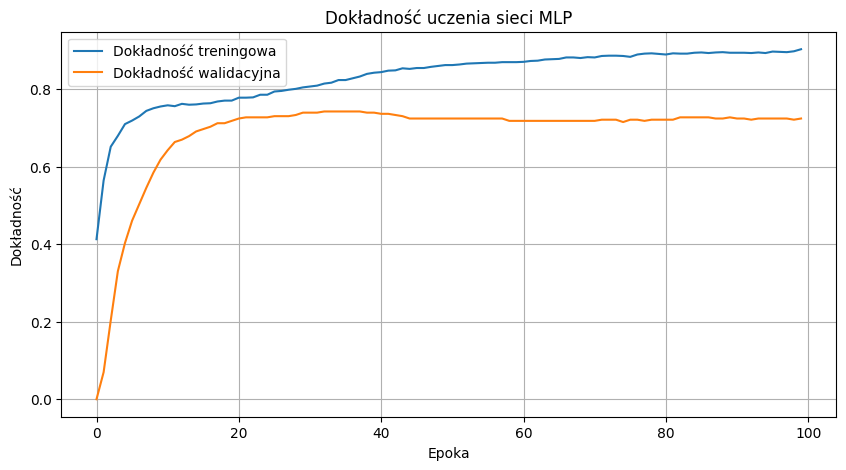

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    historia.history["accuracy"],
    label="Dokładność treningowa"
)

plt.plot(
    historia.history["val_accuracy"],
    label="Dokładność walidacyjna"
)

plt.xlabel("Epoka")
plt.ylabel("Dokładność")

plt.title("Dokładność uczenia sieci MLP")

plt.legend()
plt.grid()

plt.show()

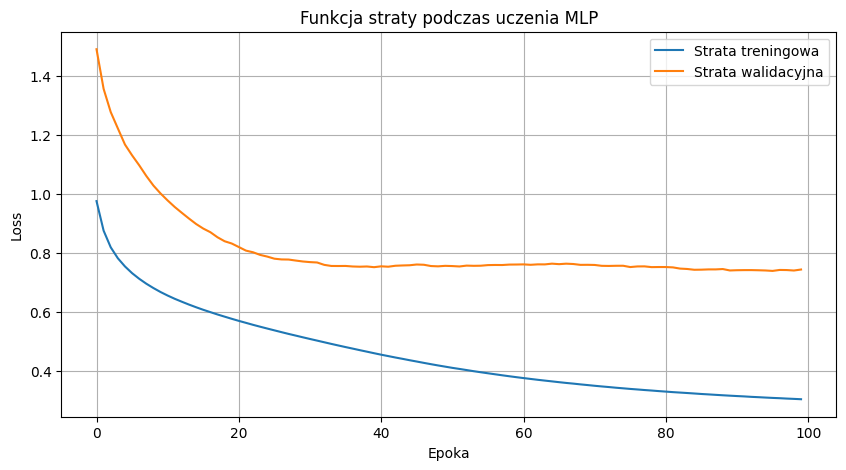

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    historia.history["loss"],
    label="Strata treningowa"
)

plt.plot(
    historia.history["val_loss"],
    label="Strata walidacyjna"
)

plt.xlabel("Epoka")
plt.ylabel("Loss")

plt.title("Funkcja straty podczas uczenia MLP")

plt.legend()
plt.grid()

plt.show()

In [15]:
loss, accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Strata testowa: {loss:.4f}")
print(f"Dokładność testowa: {accuracy * 100:.2f}%")

Strata testowa: 0.4616
Dokładność testowa: 80.67%


In [16]:
# Przewidywania sieci
y_pred = model.predict(X_test)

# Konwersja One-Hot na numery klas
y_test_int = np.argmax(y_test, axis=1)

# Wybór klasy z największym prawdopodobieństwem
y_pred_int = np.argmax(y_pred, axis=1)

print("Rzeczywiste klasy:")
print(y_test_int[:20])

print("\nPrzewidziane klasy:")
print(y_pred_int[:20])

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Rzeczywiste klasy:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Przewidziane klasy:
[0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 1]


Macierz pomyłek:
[[197  52   1]
 [ 50 250   0]
 [ 38   4 158]]


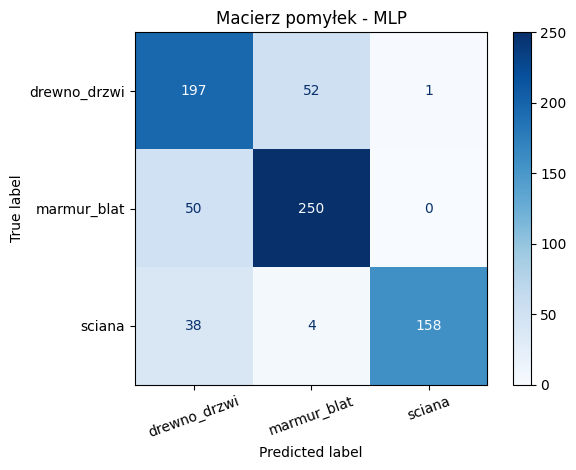

In [17]:
cm = confusion_matrix(
    y_test_int,
    y_pred_int,
    labels=[0, 1, 2]
)

print("Macierz pomyłek:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Macierz pomyłek - MLP")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [18]:
print("RAPORT KLASYFIKACJI MLP")

print(
    classification_report(
        y_test_int,
        y_pred_int,
        labels=[0, 1, 2],
        target_names=encoder.classes_,
        zero_division=0
    )
)

dokladnosc = accuracy_score(
    y_test_int,
    y_pred_int
)

print(
    f"\nDokładność końcowa MLP: "
    f"{dokladnosc * 100:.2f}%"
)

RAPORT KLASYFIKACJI MLP
              precision    recall  f1-score   support

drewno_drzwi       0.69      0.79      0.74       250
 marmur_blat       0.82      0.83      0.83       300
      sciana       0.99      0.79      0.88       200

    accuracy                           0.81       750
   macro avg       0.83      0.80      0.81       750
weighted avg       0.82      0.81      0.81       750


Dokładność końcowa MLP: 80.67%


In [19]:
dokladnosc_svm = 83.33

dokladnosc_mlp = dokladnosc * 100

print("===================================")
print("PORÓWNANIE KLASYFIKATORÓW")
print("===================================")

print(f"SVM: {dokladnosc_svm:.2f}%")
print(f"MLP: {dokladnosc_mlp:.2f}%")

roznica = dokladnosc_mlp - dokladnosc_svm

print(f"Różnica: {roznica:+.2f} punktów procentowych")

PORÓWNANIE KLASYFIKATORÓW
SVM: 83.33%
MLP: 80.67%
Różnica: -2.66 punktów procentowych
